# Defining the Problem

## Estimating diffusion parameteres of two different species in a reaction diffusion setup.

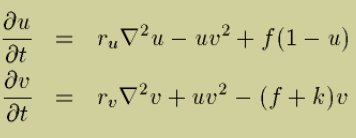

### Here r_u and r_v (diffusion coefficients) are needed to be infered using the sparse data available (exported from comsol), the above governing system and some initial and boundary conditions

## Domain -

### The space is taken as two dimensional, x and y both range between 0 and 1.
### t ranges from 0 to 3000 seconds

## Initial conditions - 

### u(x,y,t) = 0.5 for 0.45<=x<=0.55 and 0.45<=y<=0.55
### else 1

### v(x,y,t) = 0.25 for 0.45<=x<=0.55 and 0.45<=y<=0.55
### else 0

### $\frac{\partial u}{\partial t} = 0$ $\frac{\partial v}{\partial t} = 0$

## Boundary Conditions - 

### Zero flux (both for u and v) 

# Importing Libraries

In [4]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import pandas as pd

In [20]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [23]:
df = pd.read_csv('/content/drive/MyDrive/gray_scott_data/data.txt')


ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 2


In [5]:
print(torch.cuda.is_available())

True


In [6]:
# Step 1: Define problem

L = 1.0  # length of the domain
x_min, x_max = 0.0, L
y_min, y_max = 0.0, L
t_min, t_max = 0.0, 3000.0

# dimensionality
input_dim = 3   # (x, y, t)
output_dim = 1  # C only
F = 0.037
k = 0.06

Importing data

In [7]:
times = range(0, 3001, 10)

columns = ["x", "y"]

for t in times:
    columns += [f"u_{t}", f"v_{t}"]

df = pd.read_csv(
    "data.txt",
    sep=r"\s+",
    comment="%",
    header=None,
    names=columns
)



FileNotFoundError: [Errno 2] No such file or directory: 'data.txt'

In [ ]:
print(df.shape)
df.head()

(10201, 604)


,x,y,u_0,v_0,u_10,v_10,u_20,v_20,u_30,v_30,...,u_2960,v_2960,u_2970,v_2970,u_2980,v_2980,u_2990,v_2990,u_3000,v_3000
0,0.000000,0.000000,1.0,6.044687e-78,1.0,2.204048e-58,1.0,3.249821e-46,1.0,2.451408e-44,...,0.768147,0.021323,0.767991,0.021332,0.767909,0.021328,0.767634,0.021364,0.767335,0.021405
1,0.001818,0.000000,1.0,1.862587e-77,1.0,2.288148e-58,1.0,3.325602e-46,1.0,2.507647e-44,...,0.767807,0.021465,0.767650,0.021475,0.767568,0.021470,0.767293,0.021506,0.766994,0.021548
2,0.000000,0.001818,1.0,1.862587e-77,1.0,2.288148e-58,1.0,3.325602e-46,1.0,2.507647e-44,...,0.767807,0.021465,0.767650,0.021475,0.767568,0.021470,0.767293,0.021506,0.766994,0.021548
3,0.001818,0.001818,1.0,6.161572e-77,1.0,2.375532e-58,1.0,3.403211e-46,1.0,2.565221e-44,...,0.767467,0.021607,0.767310,0.021617,0.767228,0.021612,0.766952,0.021649,0.766653,0.021691
4,0.000000,0.003970,1.0,9.483544e-77,1.0,2.614471e-58,1.0,3.616293e-46,1.0,2.723311e-44,...,0.766520,0.022006,0.766363,0.022016,0.766281,0.022011,0.766004,0.022048,0.765703,0.022090


## Sampling sparse data from imported data

!! Data sampling stratergy can be different, currenlty using uniformly random

In [ ]:
# Separate u and v columns
u_df = df[["x", "y"] + [col for col in df.columns if col.startswith("u_")]]
v_df = df[["x", "y"] + [col for col in df.columns if col.startswith("v_")]]

# Randomly sample 1000 data points from each
u_sample = u_df.sample(n=1000, random_state=42)
v_sample = v_df.sample(n=1000, random_state=42)

print("u_df shape:", u_df.shape)
print("v_df shape:", v_df.shape)

print("u_sample shape:", u_sample.shape)
print("v_sample shape:", v_sample.shape)

u_df shape: (10201, 303)
v_df shape: (10201, 303)
u_sample shape: (1000, 303)
v_sample shape: (1000, 303)


In [ ]:
u_sample.head()

,x,y,u_0,u_10,u_20,u_30,u_40,u_50,u_60,u_70,...,u_2910,u_2920,u_2930,u_2940,u_2950,u_2960,u_2970,u_2980,u_2990,u_3000
5135,0.763673,0.188312,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.393441,0.391778,0.390062,0.388295,0.386477,0.384609,0.382690,0.380720,0.378677,0.376575
7921,0.993544,0.223822,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.702996,0.702442,0.701922,0.701435,0.700981,0.700559,0.700170,0.699814,0.699476,0.699166
1087,0.108312,0.015918,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.348280,0.348762,0.349267,0.349801,0.350365,0.350957,0.351579,0.352230,0.352809,0.353381
4826,0.211651,0.696141,1.0,1.0,1.0,1.0,1.0,1.0,0.999999,0.999999,...,0.586871,0.586378,0.585814,0.585178,0.584468,0.583686,0.582830,0.581902,0.581214,0.580568
10060,0.984082,0.944156,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.425550,0.425485,0.425423,0.425388,0.425381,0.425402,0.425450,0.425526,0.425361,0.425125


## Sampling Collocation points

!! Collocation points stratergy can be changed, currently using uniformly random

Normalizing everything from -1 to 1

In [ ]:
def normalize(x, xmin, xmax):
    return 2.0 * (x - xmin) / (xmax - xmin) - 1.0

In [ ]:
sx = 2.0 / (x_max - x_min)
sy = 2.0 / (y_max - y_min)
st = 2.0 / (t_max - t_min)

In [ ]:
N_collocation = 10000

# Domain limits
x_min, x_max = df["x"].min(), df["x"].max()
y_min, y_max = df["y"].min(), df["y"].max()
t_min, t_max = 0, 3000

# Random collocation points
x_col = np.random.uniform(x_min, x_max, N_collocation)
y_col = np.random.uniform(y_min, y_max, N_collocation)
t_col = np.random.uniform(t_min, t_max, N_collocation)

# Put them into a dataframe
collocation_df = pd.DataFrame({
    "x": x_col,
    "y": y_col,
    "t": t_col
})


In [ ]:
print(collocation_df.shape)
collocation_df.head()

(10000, 3)


,x,y,t
0,0.553019,0.484227,2187.469402
1,0.216953,0.355367,803.083155
2,0.016134,0.050274,2816.794987
3,0.691006,0.581235,1182.691488
4,0.330476,0.777948,243.969460


Defining gradients

In [ ]:
def gradients(C, x):
    return torch.autograd.grad(
        C,
        x,
        grad_outputs=torch.ones_like(C),
        create_graph=True,
        retain_graph=True
    )[0]

## Defining model for u(x,y,t) and v(x,y,t)

!! Hyperparameters have been chosen arbitrarily currently, can be optimized

In [ ]:
class u_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


In [ ]:
class v_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


NN for $D_u = D_u(x,y)$

!! Hyperparameters have been chosen arbitrarily currently, can be optimized

also Dv is considered constant currently

In [ ]:
class Du_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )

    def forward(self, X):
        # xy = torch.cat([x, y], dim=-1)
        return self.network(X)
    

In [ ]:
class Dv_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.Dv = nn.Parameter(torch.tensor(0.1))

    def forward(self, X):
        return self.Dv * torch.ones_like(X)  # Return a tensor of the same shape as X



# Defining different Losses

## Data Loss

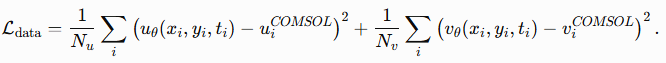

In [ ]:
times = np.arange(0, 3001, 10)

# u data
x_u = np.repeat(u_sample["x"].values, len(times))
y_u = np.repeat(u_sample["y"].values, len(times))
t_u = np.tile(times, len(u_sample))

u_true = u_sample[
    [f"u_{t}" for t in times]
].values.flatten()

# v data
x_v = np.repeat(v_sample["x"].values, len(times))
y_v = np.repeat(v_sample["y"].values, len(times))
t_v = np.tile(times, len(v_sample))

v_true = v_sample[
    [f"v_{t}" for t in times]
].values.flatten()

In [ ]:
X_u = torch.tensor(
    np.column_stack([x_u, y_u, t_u]),
    dtype=torch.float32
)

U_true = torch.tensor(
    u_true.reshape(-1, 1),
    dtype=torch.float32
)

X_v = torch.tensor(
    np.column_stack([x_v, y_v, t_v]),
    dtype=torch.float32
)

V_true = torch.tensor(
    v_true.reshape(-1, 1),
    dtype=torch.float32
)

In [ ]:
def data_loss(u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max):

    # Normalize inputs
    X_u_norm = X_u.clone()
    X_v_norm = X_v.clone()

    X_u_norm[:, 0] = normalize(X_u[:, 0], x_min, x_max)
    X_u_norm[:, 1] = normalize(X_u[:, 1], y_min, y_max)
    X_u_norm[:, 2] = normalize(X_u[:, 2], t_min, t_max)

    X_v_norm[:, 0] = normalize(X_v[:, 0], x_min, x_max)
    X_v_norm[:, 1] = normalize(X_v[:, 1], y_min, y_max)
    X_v_norm[:, 2] = normalize(X_v[:, 2], t_min, t_max)

    # Predictions
    U_pred = u_net(X_u_norm)
    V_pred = v_net(X_v_norm)

    # MSE
    loss_u = torch.mean((U_pred - U_true) ** 2)
    loss_v = torch.mean((V_pred - V_true) ** 2)

    return loss_u + loss_v

PDE loss

In [ ]:
def pde_loss(
    u_net, v_net, Du_net,
    X_col,
    Dv_net, F, k,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # --------------------------------------------------
    # Normalization factors
    # --------------------------------------------------

    sx = 2.0 / (x_max - x_min)
    sy = 2.0 / (y_max - y_min)
    st = 2.0 / (t_max - t_min)

    # --------------------------------------------------
    # Normalize collocation points
    # --------------------------------------------------

    X_raw = X_col.clone().requires_grad_(True)

    x = normalize(X_raw[:, 0:1], x_min, x_max)
    y = normalize(X_raw[:, 1:2], y_min, y_max)
    t = normalize(X_raw[:, 2:3], t_min, t_max)

    X = torch.cat([x, y, t], dim=1)

    # --------------------------------------------------
    # Network predictions
    # --------------------------------------------------

    u = u_net(X)
    v = v_net(X)

    # D = D(x,y)
    D = Du_net(X[:, 0:2])
    Dv = Dv_net(X[:, 0:2])

    # --------------------------------------------------
    # First derivatives of u
    # --------------------------------------------------

    u_grad = torch.autograd.grad(
        u,
        X,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xn = u_grad[:, 0:1]
    u_yn = u_grad[:, 1:2]
    u_tn = u_grad[:, 2:3]

    # Convert to physical derivatives
    u_x = sx * u_xn
    u_y = sy * u_yn
    u_t = st * u_tn

    # --------------------------------------------------
    # Second derivatives of u
    # --------------------------------------------------

    u_xn_xn = torch.autograd.grad(
        u_xn,
        X,
        grad_outputs=torch.ones_like(u_xn),
        create_graph=True
    )[0][:, 0:1]

    u_yn_yn = torch.autograd.grad(
        u_yn,
        X,
        grad_outputs=torch.ones_like(u_yn),
        create_graph=True
    )[0][:, 1:2]

    # Convert to physical second derivatives
    u_xx = sx**2 * u_xn_xn
    u_yy = sy**2 * u_yn_yn

    # --------------------------------------------------
    # Derivatives of D(x,y)
    # --------------------------------------------------

    D_grad = torch.autograd.grad(
        D,
        X,
        grad_outputs=torch.ones_like(D),
        create_graph=True
    )[0]

    D_xn = D_grad[:, 0:1]
    D_yn = D_grad[:, 1:2]

    # Convert to physical derivatives
    D_x = sx * D_xn
    D_y = sy * D_yn

    # --------------------------------------------------
    # First derivatives of v
    # --------------------------------------------------

    v_grad = torch.autograd.grad(
        v,
        X,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    v_xn = v_grad[:, 0:1]
    v_yn = v_grad[:, 1:2]
    v_tn = v_grad[:, 2:3]

    # Physical derivatives
    v_x = sx * v_xn
    v_y = sy * v_yn
    v_t = st * v_tn

    # --------------------------------------------------
    # Second derivatives of v
    # --------------------------------------------------

    v_xn_xn = torch.autograd.grad(
        v_xn,
        X,
        grad_outputs=torch.ones_like(v_xn),
        create_graph=True
    )[0][:, 0:1]

    v_yn_yn = torch.autograd.grad(
        v_yn,
        X,
        grad_outputs=torch.ones_like(v_yn),
        create_graph=True
    )[0][:, 1:2]

    # Physical second derivatives
    v_xx = sx**2 * v_xn_xn
    v_yy = sy**2 * v_yn_yn

    # --------------------------------------------------
    # Diffusion terms
    # --------------------------------------------------

    # div(D grad(u))
    diffusion_u = (
        D * (u_xx + u_yy)
        + D_x * u_x
        + D_y * u_y
    )

    # Dv is constant
    diffusion_v = Dv * (v_xx + v_yy)

    # --------------------------------------------------
    # Gray-Scott reaction terms
    # --------------------------------------------------

    reaction_u = -u * v**2 + F * (1.0 - u)

    reaction_v = u * v**2 - (F + k) * v

    # --------------------------------------------------
    # PDE residuals
    # --------------------------------------------------

    f_u = u_t - diffusion_u - reaction_u

    f_v = v_t - diffusion_v - reaction_v

    # --------------------------------------------------
    # PDE loss
    # --------------------------------------------------

    loss_u = torch.mean(f_u**2)
    loss_v = torch.mean(f_v**2)

    loss_pde = loss_u + loss_v

    return loss_pde

Initial condition Loss

!! Currently the stratergy is to specify the fraction of points that must be sampled from the square and outside the square

In [ ]:
def sample_initial_points(
    N_ic,
    x_min, x_max,
    y_min, y_max,
    t_min,
    inside_fraction=0.25
):
    """
    Samples points at t = t_min.

    inside_fraction:
        Fraction of points sampled inside
        0.45 <= x <= 0.55 and 0.45 <= y <= 0.55
    """

    N_inside = int(N_ic * inside_fraction)
    N_outside = N_ic - N_inside

    # ---------------------------------------------
    # Sample points inside the central square
    # ---------------------------------------------

    x_inside = torch.rand(N_inside, 1) * 0.10 + 0.45
    y_inside = torch.rand(N_inside, 1) * 0.10 + 0.45

    # ---------------------------------------------
    # Sample points outside the central square
    # ---------------------------------------------

    x_outside_list = []
    y_outside_list = []

    while sum(len(x) for x in x_outside_list) < N_outside:

        N_remaining = N_outside - sum(
            len(x) for x in x_outside_list
        )

        x_new = (
            torch.rand(N_remaining, 1)
            * (x_max - x_min)
            + x_min
        )

        y_new = (
            torch.rand(N_remaining, 1)
            * (y_max - y_min)
            + y_min
        )

        outside_mask = ~(
            (x_new >= 0.45) & (x_new <= 0.55) &
            (y_new >= 0.45) & (y_new <= 0.55)
        )

        x_outside_list.append(x_new[outside_mask].reshape(-1, 1))
        y_outside_list.append(y_new[outside_mask].reshape(-1, 1))

    x_outside = torch.cat(x_outside_list)[:N_outside]
    y_outside = torch.cat(y_outside_list)[:N_outside]

    # ---------------------------------------------
    # Combine points
    # ---------------------------------------------

    x = torch.cat([x_inside, x_outside], dim=0)
    y = torch.cat([y_inside, y_outside], dim=0)

    # All points are at t = t_min
    t = torch.full_like(x, t_min)

    # ---------------------------------------------
    # Target values
    # ---------------------------------------------

    u_true = torch.cat([
        torch.full((N_inside, 1), 0.5),
        torch.full((N_outside, 1), 1.0)
    ])

    v_true = torch.cat([
        torch.full((N_inside, 1), 0.25),
        torch.full((N_outside, 1), 0.0)
    ])

    return x, y, t, u_true, v_true

In [ ]:
x_ic, y_ic, t_ic, u_ic, v_ic = sample_initial_points(
    N_ic=2000,
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    t_min=t_min,
    inside_fraction=0.25
)

In [ ]:
def initial_condition_loss(
    u_net,
    v_net,
    x, y, t,
    u_true, v_true,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # Normalize inputs
    x_n = normalize(x, x_min, x_max)
    y_n = normalize(y, y_min, y_max)
    t_n = normalize(t, t_min, t_max)

    X_ic = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_ic)
    v_pred = v_net(X_ic)

    # Losses
    loss_u = torch.mean((u_pred - u_true) ** 2)
    loss_v = torch.mean((v_pred - v_true) ** 2)

    loss_ic = loss_u + loss_v

    return loss_ic

## Boundary condition Loss

In [ ]:
def sample_boundary_points(
    N_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):
    """
    Randomly samples points on all four boundaries
    over the full time domain.

    Returns:
        x_bc, y_bc, t_bc
    """

    # Divide points approximately equally among 4 boundaries
    N_left = N_bc // 4
    N_right = N_bc // 4
    N_bottom = N_bc // 4
    N_top = N_bc - N_left - N_right - N_bottom

    # ---------------------------------------------
    # Left boundary: x = x_min
    # ---------------------------------------------

    x_left = torch.full((N_left, 1), x_min)
    y_left = torch.rand(N_left, 1) * (y_max - y_min) + y_min
    t_left = torch.rand(N_left, 1) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Right boundary: x = x_max
    # ---------------------------------------------

    x_right = torch.full((N_right, 1), x_max)
    y_right = torch.rand(N_right, 1) * (y_max - y_min) + y_min
    t_right = torch.rand(N_right, 1) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Bottom boundary: y = y_min
    # ---------------------------------------------

    x_bottom = torch.rand(N_bottom, 1) * (x_max - x_min) + x_min
    y_bottom = torch.full((N_bottom, 1), y_min)
    t_bottom = torch.rand(N_bottom, 1) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Top boundary: y = y_max
    # ---------------------------------------------

    x_top = torch.rand(N_top, 1) * (x_max - x_min) + x_min
    y_top = torch.full((N_top, 1), y_max)
    t_top = torch.rand(N_top, 1) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Combine
    # ---------------------------------------------

    x_bc = torch.cat([
        x_left,
        x_right,
        x_bottom,
        x_top
    ], dim=0)

    y_bc = torch.cat([
        y_left,
        y_right,
        y_bottom,
        y_top
    ], dim=0)

    t_bc = torch.cat([
        t_left,
        t_right,
        t_bottom,
        t_top
    ], dim=0)

    return x_bc, y_bc, t_bc

In [ ]:
x_bc, y_bc, t_bc = sample_boundary_points(
    1000,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
)

In [ ]:
def boundary_condition_loss(
    u_net,
    v_net,
    x_bc, y_bc, t_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # ---------------------------------------------
    # Normalization factors
    # ---------------------------------------------

    sx = 2.0 / (x_max - x_min)
    sy = 2.0 / (y_max - y_min)

    # ---------------------------------------------
    # Normalize coordinates
    # ---------------------------------------------

    x_n = normalize(x_bc, x_min, x_max)
    y_n = normalize(y_bc, y_min, y_max)
    t_n = normalize(t_bc, t_min, t_max)

    X_bc = torch.cat([x_n, y_n, t_n], dim=1)
    X_bc.requires_grad_(True)

    # ---------------------------------------------
    # Network predictions
    # ---------------------------------------------

    u = u_net(X_bc)
    v = v_net(X_bc)

    # ---------------------------------------------
    # Gradients of u
    # ---------------------------------------------

    u_grad = torch.autograd.grad(
        u,
        X_bc,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xn = u_grad[:, 0:1]
    u_yn = u_grad[:, 1:2]

    # Convert to physical derivatives
    u_x = sx * u_xn
    u_y = sy * u_yn

    # ---------------------------------------------
    # Gradients of v
    # ---------------------------------------------

    v_grad = torch.autograd.grad(
        v,
        X_bc,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    v_xn = v_grad[:, 0:1]
    v_yn = v_grad[:, 1:2]

    # Convert to physical derivatives
    v_x = sx * v_xn
    v_y = sy * v_yn

    # ---------------------------------------------
    # Determine which points are on which boundary
    # ---------------------------------------------

    left = torch.isclose(x_bc, torch.tensor(float(x_min)))
    right = torch.isclose(x_bc, torch.tensor(float(x_max)))
    bottom = torch.isclose(y_bc, torch.tensor(float(y_min)))
    top = torch.isclose(y_bc, torch.tensor(float(y_max)))

    # ---------------------------------------------
    # Normal derivatives
    # ---------------------------------------------

    # On x boundaries: normal derivative = x derivative
    u_normal_x = torch.cat([
        u_x[left],
        u_x[right]
    ])

    v_normal_x = torch.cat([
        v_x[left],
        v_x[right]
    ])

    # On y boundaries: normal derivative = y derivative
    u_normal_y = torch.cat([
        u_y[bottom],
        u_y[top]
    ])

    v_normal_y = torch.cat([
        v_y[bottom],
        v_y[top]
    ])

    # ---------------------------------------------
    # Zero-flux loss
    # ---------------------------------------------

    loss_u = (
        torch.mean(u_normal_x**2)
        + torch.mean(u_normal_y**2)
    )

    loss_v = (
        torch.mean(v_normal_x**2)
        + torch.mean(v_normal_y**2)
    )

    loss_bc = loss_u + loss_v

    return loss_bc

## Aggregating losses

In [ ]:
def total_loss(
    u_net,
    v_net,
    D_net,
    Dv_net,
    F,
    k,

    # Data points
    X_u,
    U_true,
    X_v,
    V_true,

    # Initial-condition points
    x_ic,
    y_ic,
    t_ic,
    u_ic_true,
    v_ic_true,

    # Boundary-condition points
    x_bc,
    y_bc,
    t_bc,

    # Collocation points
    X_col,

    # Loss weights
    lambda_data=1.0,
    lambda_ic=1.0,
    lambda_bc=1.0,
    lambda_pde=1.0,

    # Domain
    x_min=0.0,
    x_max=1.0,
    y_min=0.0,
    y_max=1.0,
    t_min=0.0,
    t_max=3000.0
):

    # 1. Data loss
    L_data = data_loss(
        u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 2. Initial-condition loss
    L_ic = initial_condition_loss(
        u_net,
        v_net,
        x_ic,
        y_ic,
        t_ic,
        u_ic_true,
        v_ic_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 3. Boundary-condition loss
    L_bc = boundary_condition_loss(
        u_net,
        v_net,
        x_bc,
        y_bc,
        t_bc,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 4. PDE loss
    L_pde = pde_loss(
        u_net,
        v_net,
        D_net,
        X_col,
        Dv_net,
        F,
        k,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # Weighted total loss
    L_total = (
        lambda_data * L_data
        + lambda_ic * L_ic
        + lambda_bc * L_bc
        + lambda_pde * L_pde
    )

    return L_total, L_data, L_ic, L_bc, L_pde

# The Training Loop

## Creating instances of NNs

In [ ]:
u_nn = u_net()
v_nn = v_net()
Du_nn = Du_net()
Dv_nn = Dv_net()

## Pre-training

Splitting data into mini batches

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

data_dataset = TensorDataset(
    X_u,
    U_true,
    V_true
)

In [ ]:
batch_size = 4096

data_loader = DataLoader(
    data_dataset,
    batch_size=batch_size,
    shuffle=True
)

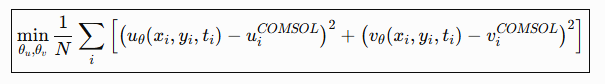

In [ ]:
def pretraining_loss(
    u_net,
    v_net,
    X_batch,
    U_true_batch,
    V_true_batch,
    x_min,
    x_max,
    y_min,
    y_max,
    t_min,
    t_max
):

    # Normalize inputs
    x_n = normalize(X_batch[:, 0:1], x_min, x_max)
    y_n = normalize(X_batch[:, 1:2], y_min, y_max)
    t_n = normalize(X_batch[:, 2:3], t_min, t_max)

    X_norm = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_norm)
    v_pred = v_net(X_norm)

    # Data losses
    loss_u = torch.mean((u_pred - U_true_batch) ** 2)
    loss_v = torch.mean((v_pred - V_true_batch) ** 2)

    # Total pre-training loss
    loss = loss_u + loss_v

    return loss, loss_u, loss_v

In [ ]:
num_epochs = 100

optimizer_pretrain = torch.optim.Adam(
    list(u_nn.parameters()) +
    list(v_nn.parameters()),
    lr=1e-3
)

for epoch in range(num_epochs):

    epoch_loss = 0.0
    epoch_loss_u = 0.0
    epoch_loss_v = 0.0

    for X_batch, U_true_batch, V_true_batch in data_loader:

        # Forward + loss
        loss, loss_u, loss_v = pretraining_loss(
            u_nn,
            v_nn,
            X_batch,
            U_true_batch,
            V_true_batch,
            x_min=0.0,
            x_max=1.0,
            y_min=0.0,
            y_max=1.0,
            t_min=0.0,
            t_max=3000.0
        )

        # Backpropagation
        optimizer_pretrain.zero_grad()

        loss.backward()

        optimizer_pretrain.step()

        # Accumulate losses
        epoch_loss += loss.item()
        epoch_loss_u += loss_u.item()
        epoch_loss_v += loss_v.item()

    # Average over mini-batches
    epoch_loss /= len(data_loader)
    epoch_loss_u /= len(data_loader)
    epoch_loss_v /= len(data_loader)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Total: {epoch_loss:.6e} | "
            f"u: {epoch_loss_u:.6e} | "
            f"v: {epoch_loss_v:.6e}"
        )

Epoch [10/100] Total: 3.273296e-02 | u: 2.281852e-02 | v: 9.914442e-03
Epoch [20/100] Total: 2.812030e-02 | u: 1.857996e-02 | v: 9.540338e-03
Epoch [30/100] Total: 2.017562e-02 | u: 1.259470e-02 | v: 7.580919e-03
Epoch [40/100] Total: 1.748532e-02 | u: 1.098741e-02 | v: 6.497912e-03
Epoch [50/100] Total: 1.547120e-02 | u: 9.311473e-03 | v: 6.159730e-03
Epoch [60/100] Total: 1.329943e-02 | u: 7.378843e-03 | v: 5.920585e-03


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x00000263ECFAC1D0>>
Traceback (most recent call last):
  File "C:\Users\Karan\AppData\Roaming\Python\Python311\site-packages\ipykernel\ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


KeyboardInterrupt: 

## Main training Loop

Collocation point sampling

!! Currently sampling new collocation points for each epoch

In [ ]:
def sample_collocation_points(N_col, x_min, x_max, y_min, y_max, t_min, t_max):
    x = torch.rand(N_col, 1) * (x_max - x_min) + x_min
    y = torch.rand(N_col, 1) * (y_max - y_min) + y_min
    t = torch.rand(N_col, 1) * (t_max - t_min) + t_min
    return torch.cat([x, y, t], dim=1)

Hyper params

In [ ]:
num_epochs = 500

N_col = 5000
N_ic = 2000
N_bc = 2000

optimizer = torch.optim.Adam(
    list(u_nn.parameters()) +
    list(v_nn.parameters()) +
    list(Du_nn.parameters()) +
    list(Dv_nn.parameters()),
    lr=1e-3
)

loss weights

!! currently all lambdas are constant

In [ ]:
lambda_data = 1.0
lambda_ic = 1.0
lambda_bc = 1.0
lambda_pde = 1.0

## Final Loop

In [ ]:
for epoch in range(num_epochs):

    epoch_total = 0.0

    # -----------------------------------------
    # 1. Data loss (mini-batch)
    # -----------------------------------------
    for X_batch, U_batch, V_batch in data_loader:

        L_data = data_loss(
            u_nn, v_nn,
            X_batch, U_batch,
            X_batch, V_batch,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # -----------------------------------------
        # 2. IC loss (resampled each batch)
        # -----------------------------------------
        x_ic, y_ic, t_ic, u_ic, v_ic = sample_initial_points(
            N_ic,
            x_min, x_max,
            y_min, y_max,
            t_min,
            inside_fraction=0.25
        )

        L_ic = initial_condition_loss(
            u_nn, v_nn,
            x_ic, y_ic, t_ic,
            u_ic, v_ic,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # -----------------------------------------
        # 3. BC loss (resampled each batch)
        # -----------------------------------------
        x_bc, y_bc, t_bc = sample_boundary_points(
            N_bc,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        L_bc = boundary_condition_loss(
            u_nn, v_nn,
            x_bc, y_bc, t_bc,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # -----------------------------------------
        # 4. PDE loss (fresh collocation)
        # -----------------------------------------
        X_col = sample_collocation_points(
            N_col,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        L_pde = pde_loss(
            u_nn, v_nn, Du_nn,
            X_col,
            Dv_nn, F, k,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # -----------------------------------------
        # TOTAL LOSS
        # -----------------------------------------
        L = (
            lambda_data * L_data +
            lambda_ic * L_ic +
            lambda_bc * L_bc +
            lambda_pde * L_pde
        )

        optimizer.zero_grad()
        L.backward()
        optimizer.step()

        epoch_total += L.item()

    # -----------------------------------------
    # Logging
    # -----------------------------------------
    if (epoch + 1) % 10 == 0:
        print(f"""
        Epoch {epoch+1}/{num_epochs}
        Total Loss: {epoch_total/len(data_loader):.6e}
        """)


        Epoch 10/500
        Total Loss: 1.140326e+00
        

        Epoch 20/500
        Total Loss: 1.140336e+00
        


KeyboardInterrupt: 